# 01 - Exploration: macro events, news sentiment and strategy permutations

This notebook walks the pipeline step by step. It uses **live data** if `data/processed/events.csv` and
`data/raw/trade_logs.csv` exist, otherwise it falls back to **synthetic demo data** (set `FORCE_DEMO = True` to force it).

1. Load inputs  2. Calendar & timezone alignment  3. Surprises  4. News sentiment  5. Feature panel
6. Walk-forward validation  7. Visual matrices

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src import config, pipeline
from src.features.macro_features import add_surprise_z, score_news
from src.modeling.metrics import summarize_returns, regression_metrics
from src.visualization import macro_matrix

pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
FORCE_DEMO = False
live_ready = (config.PROCESSED_DIR / "events.csv").exists() and config.TRADE_LOGS_PATH.exists()
demo = FORCE_DEMO or not live_ready
events, news, trades, mode = pipeline.load_inputs(demo=demo)
print("data mode:", mode, "| events", len(events), "| articles", len(news), "| trades", len(trades))

data mode: demo | events 31 | articles 439 | trades 7125


## 1. Macro calendar - UTC / New York alignment
Every release carries both `event_time_utc` and `event_time_est` (America/New_York, so EST/EDT is handled automatically).

In [2]:
events[["event_time_utc","event_time_est","event_type","event_name","actual","forecast","surprise"]].tail(12)

,event_time_utc,event_time_est,event_type,event_name,actual,forecast,surprise
19,2026-08-12 12:30:00+00:00,2026-08-12 08:30:00-04:00,CPI,Core CPI m/m,0.10,0.30,-0.20
20,2026-08-12 12:30:00+00:00,2026-08-12 08:30:00-04:00,CPI,CPI m/m,0.20,0.30,-0.10
21,2026-08-25 18:00:00+00:00,2026-08-25 14:00:00-04:00,FOMC,FOMC Interest Rate Decision,5.50,5.25,0.25
22,2026-09-04 12:30:00+00:00,2026-09-04 08:30:00-04:00,EMPLOYMENT,Nonfarm Payrolls,166000.00,169000.00,-3000.00
23,2026-09-04 12:30:00+00:00,2026-09-04 08:30:00-04:00,EMPLOYMENT,Unemployment Rate,3.90,3.90,0.00
24,2026-09-14 12:30:00+00:00,2026-09-14 08:30:00-04:00,CPI,CPI m/m,0.20,0.20,0.00
25,2026-09-14 12:30:00+00:00,2026-09-14 08:30:00-04:00,CPI,Core CPI m/m,0.20,0.20,0.00
26,2026-10-02 12:30:00+00:00,2026-10-02 08:30:00-04:00,EMPLOYMENT,Nonfarm Payrolls,124000.00,183000.00,-59000.00
27,2026-10-02 12:30:00+00:00,2026-10-02 08:30:00-04:00,EMPLOYMENT,Unemployment Rate,4.10,4.00,0.10
28,2026-10-06 18:00:00+00:00,2026-10-06 14:00:00-04:00,FOMC,FOMC Interest Rate Decision,5.25,5.25,0.00


In [3]:
print(events.groupby("event_type").size().rename("releases").to_frame())
# sanity check: US data releases at 08:30 / 14:00 New York time regardless of DST
print(events["event_time_est"].dt.strftime("%H:%M").value_counts().head())

            releases
event_type          
CPI               14
EMPLOYMENT        12
FOMC               5
event_time_est
08:30    26
14:00     5
Name: count, dtype: int64


## 2. Surprises (actual - forecast), standardised with *past* releases only

In [4]:
ev = add_surprise_z(events)
fig, ax = plt.subplots(figsize=(11, 3.5))
for t, g in ev.dropna(subset=["surprise_z"]).groupby("event_type"):
    ax.scatter(g["event_date"], g["surprise_z"], label=t, s=45)
ax.axhline(0, color="grey", lw=.8); ax.set_ylabel("surprise z"); ax.legend(ncol=5); ax.set_title("Release surprises")
plt.show()

## 3. News sentiment
Keyword lexicon -> `hawk_dove` (+ hawkish) and `risk_sent` (+ risk-on) per article, then a daily EWM.

In [5]:
sc = score_news(news)
print(sc[["date","source","title","hawk_dove","risk_sent"]].tail(5).to_string(index=False))
daily_scores = sc.groupby("date")[["hawk_dove","risk_sent"]].mean()
daily_scores.ewm(halflife=3).mean().plot(figsize=(11,3.5), title="Daily news sentiment (EWM)"); plt.show()

      date source                                                                                            title  hawk_dove  risk_sent
2026-10-07   demo Disinflation trend supports easing outlook; Stocks rally on resilient growth and upbeat earnings       -1.0        1.0
2026-10-07   demo                     Disinflation trend supports easing outlook; Equities gain as optimism builds       -1.0        1.0
2026-10-07   demo                     Disinflation trend supports easing outlook; Equities gain as optimism builds       -1.0        1.0
2026-10-08   demo                        Cooling inflation boosts rate cut hopes; Equities gain as optimism builds       -1.0        1.0
2026-10-08   demo    Cooling inflation boosts rate cut hopes; Stocks rally on resilient growth and upbeat earnings       -1.0        1.0


## 4. Feature panel (date x permutation)
Realised information is lagged one day; scheduled calendar flags are not (they are known in advance).

In [6]:
feats = pipeline.build_features(events, news, trades)
panel, feature_cols = feats["panel"], feats["feature_cols"]
print("panel:", panel.shape, "| features:", len(feature_cols), "| permutations:", panel["permutation_id"].nunique())
print(feature_cols)
panel[panel["is_future"] == 0].sample(5, random_state=1)[["date","permutation_id","y"] + feature_cols[:6]]

panel: (3510, 52) | features: 41 | permutations: 27
['ret_lag1', 'mean_pnl_5', 'vol_pnl_5', 'win_rate_5', 'mean_pnl_20', 'vol_pnl_20', 'win_rate_20', 'n_trades_5', 'rank_mean_pnl_20', 'mkt_mean_pnl_5', 'lookback', 'stop_loss', 'take_profit', 'is_fomc_day', 'is_cpi_day', 'is_pce_day', 'is_employment_day', 'is_gdp_day', 'n_events', 'is_event_day', 'days_to_next_event', 'days_since_last_event', 'hawkish_surprise_lag1', 'surprise_ewm', 'cpi_surprise_last', 'employment_surprise_last', 'hawk_dove_ewm', 'risk_sent_ewm', 'sent_change_5d', 'news_volume_7d', 'dow', 'day_of_month', 'week_of_month', 'month', 'is_month_end', 'is_month_start', 'is_quarter_end_month', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos']


,date,permutation_id,y,ret_lag1,mean_pnl_5,vol_pnl_5,win_rate_5,mean_pnl_20,vol_pnl_20
1965,2026-05-04,L20_SL2.0_TP1.0,-0.241873,0.000000,0.024466,0.931713,0.600000,-0.106929,0.703685
1246,2026-07-28,L20_SL0.5_TP1.0,-0.907642,-1.333145,-0.346579,1.152183,0.285714,-0.112317,0.700956
1027,2026-09-23,L10_SL2.0_TP2.0,0.252057,0.392822,-0.094282,0.462806,0.600000,-0.024341,0.513656
3246,2026-10-06,L50_SL2.0_TP1.0,0.486778,-0.508811,0.047264,0.771810,0.555556,0.049913,0.659275
303,2026-06-11,L10_SL0.5_TP3.0,-0.211561,-0.453879,-0.754070,1.265904,0.300000,-0.416336,0.967146


In [7]:
# Does P&L differ on event days? (descriptive only - the model learns this properly)
h = panel[panel.is_future == 0]
print(h.groupby("is_event_day")["y"].agg(["mean", "std", "count"]).round(4))
print(h.groupby(["is_cpi_day"])["y"].mean().round(4))

                mean     std  count
is_event_day                       
0            -0.0190  0.8583   3024
1             0.0494  0.8657    459
is_cpi_day
0   -0.0125
1    0.0417
Name: y, dtype: float64


## 5. Walk-forward validation

In [8]:
wf, summary, reg, final, recs = pipeline.run_model(feats, "hgb")
print(f"{wf.n_folds} folds, OOS {wf.returns.index.min().date()} -> {wf.returns.index.max().date()}")
summary.round(3)

18 folds, OOS 2026-06-08 -> 2026-10-08


,n_days,total_pnl_%,mean_daily_%,ann_vol_%,sharpe,sortino,max_drawdown,hit_rate
model_topk,89.0,5.217,0.059,5.165,2.860,4.972,-0.013,0.551
trailing_topk,89.0,4.014,0.045,6.103,1.862,2.918,-0.022,0.584
equal_weight,89.0,-1.208,-0.014,2.744,-1.247,-1.642,-0.021,0.472
model_bottomk,89.0,-2.211,-0.025,6.438,-0.972,-1.334,-0.042,0.427


In [9]:
pd.Series(reg).round(4).to_frame("out-of-sample")

,out-of-sample
n_predictions,2403.0000
rmse,0.8794
mae,0.6481
r2,-0.0303
mean_rank_ic,0.0373
ic_ir,0.2105
ic_positive_days,0.5506
direction_accuracy,0.4507


In [10]:
wf.returns.cumsum().plot(figsize=(11,4), title="Out-of-sample cumulative P&L (%)"); plt.axhline(0,color="grey",lw=.8); plt.show()
recs.assign(date=recs["date"].dt.date)

,date,permutation_id,lookback,stop_loss,take_profit,pred_pnl_%
0,2026-10-09,L10_SL2.0_TP1.0,10,2.0,1.0,0.267659
1,2026-10-09,L10_SL0.5_TP2.0,10,0.5,2.0,0.228363
2,2026-10-09,L10_SL2.0_TP2.0,10,2.0,2.0,0.189597
3,2026-10-09,L10_SL0.5_TP3.0,10,0.5,3.0,0.176514
4,2026-10-09,L20_SL2.0_TP3.0,20,2.0,3.0,0.159594


## 6. Visual matrices

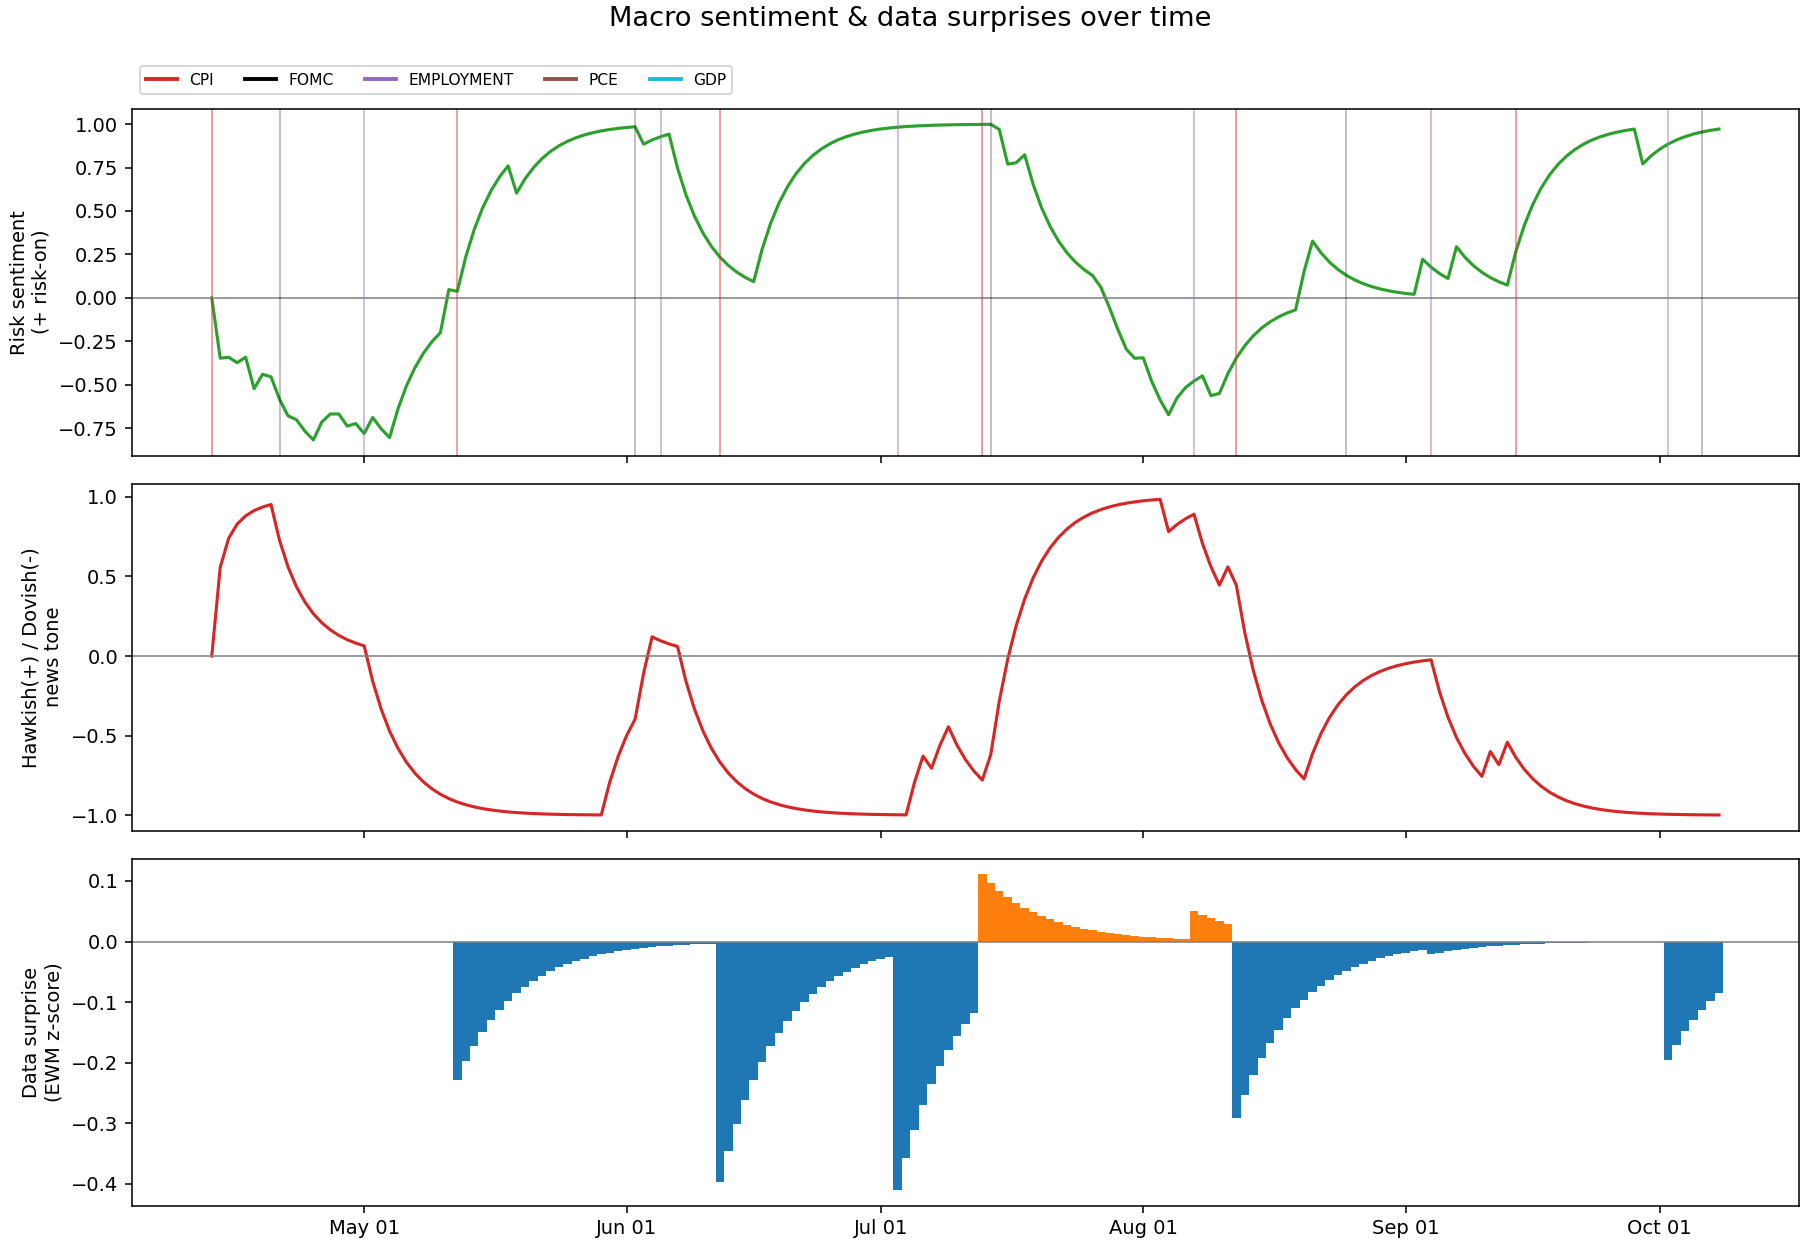

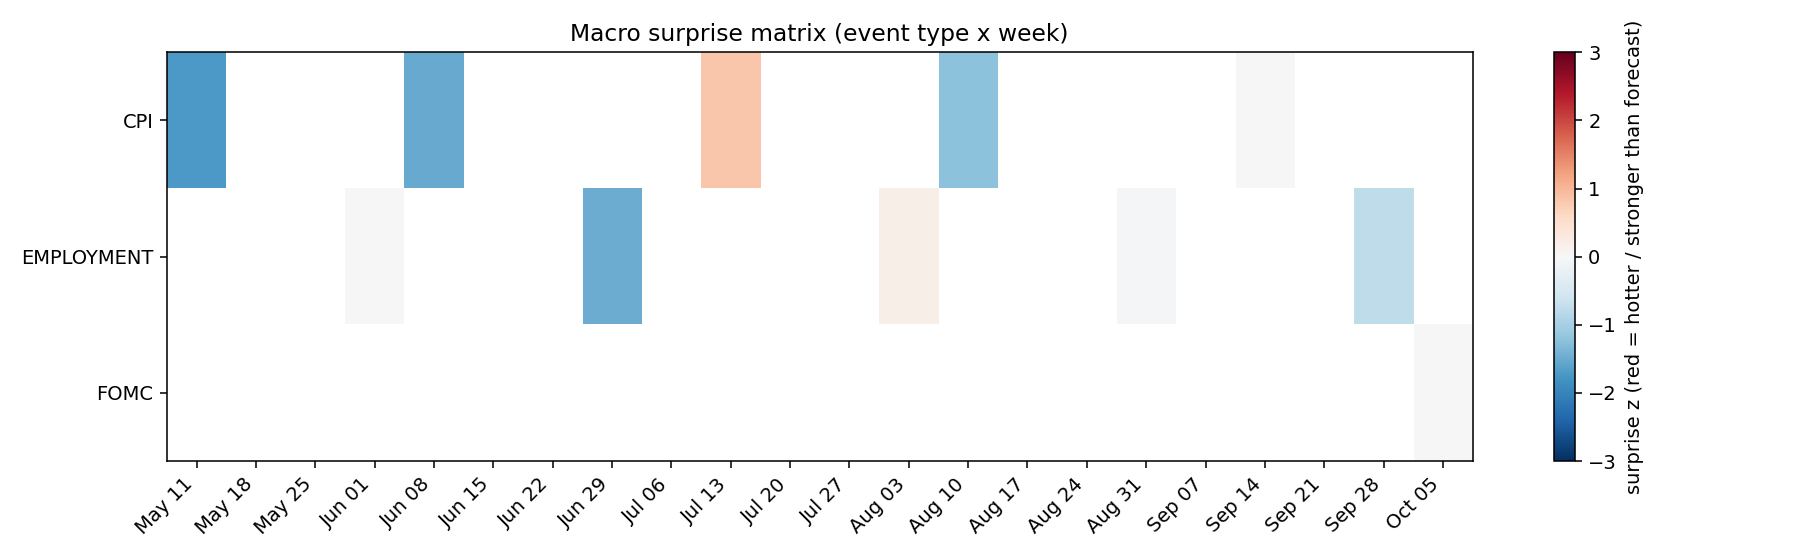

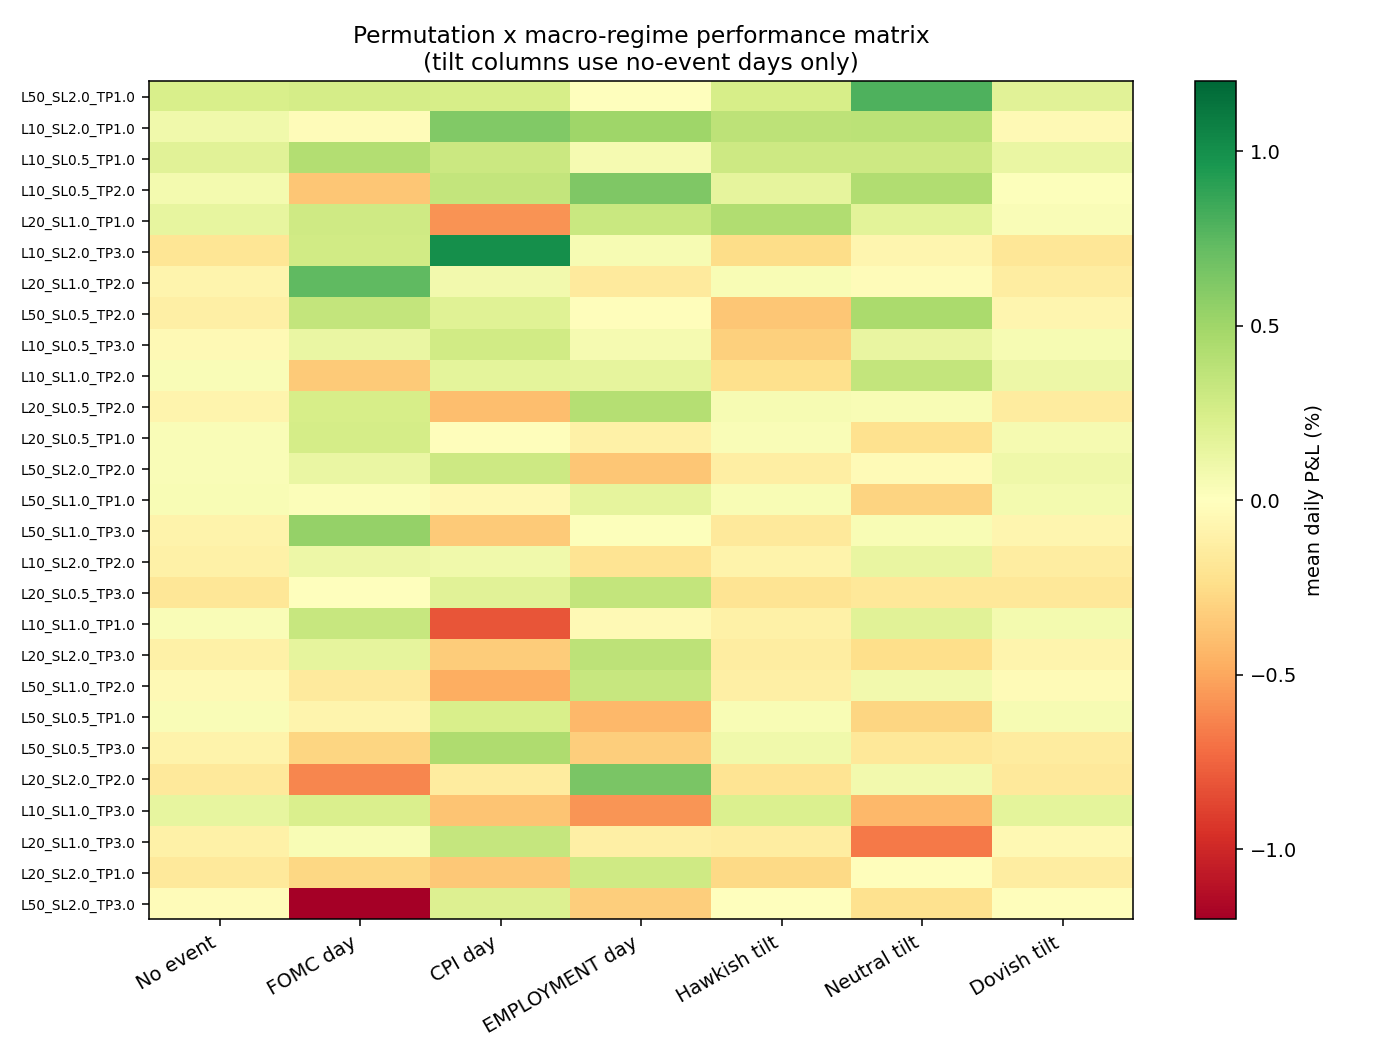

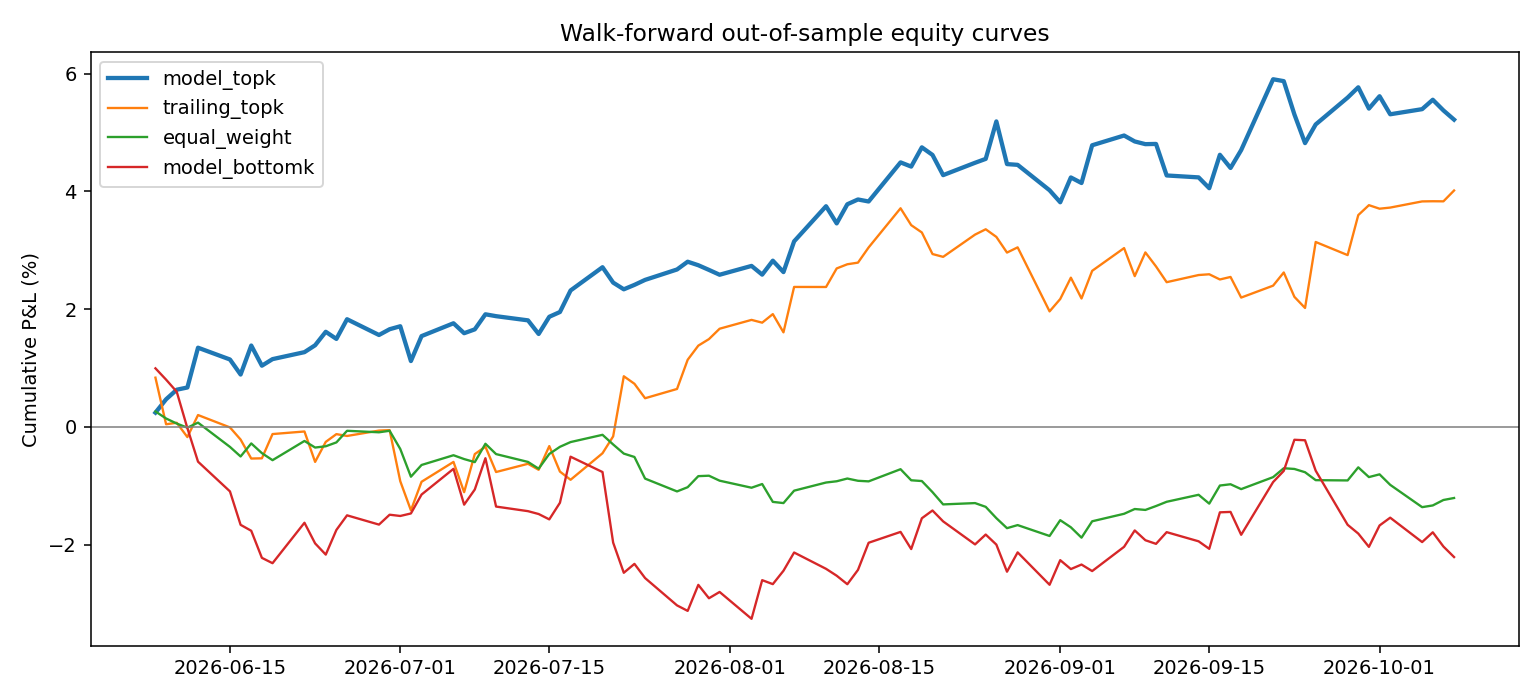

In [11]:
figs = macro_matrix.make_all(feats["daily_macro"], events, panel, wf.returns)
for f in figs: display(Image(filename=str(f)))

## Notes
* Demo results are not evidence of edge - they only prove the plumbing. Re-run on real trade logs.
* Check for leakage whenever you add a feature: `tests/test_walk_forward_leakage.py` shows the pattern.
* With ~180 days there are only a handful of CPI/FOMC/jobs events - treat event-specific effects cautiously.